# 04 · YOLO detector on dataset v1.2: where is the problem, and what is it?

Stage 2 of the screening pipeline. Stage 1 (`03_issue_classifier_v12.ipynb`) says *whether* a mouth photo shows a
problem; this model draws boxes around each finding and names it:

| id | class | in the app's feature list? |
|---|---|---|
| 0 | Calculus | yes |
| 1 | Caries | yes |
| 2 | Hypodontia (missing teeth) | yes |
| 3 | Mouth_Ulcer | yes |
| 4 | Tooth_Discoloration | yes |

**Data:** `datasets/oral_datasetv1.2/pool` (see its README). Compared with v1.1 (notebook 02):
- Roboflow photos are the clean originals (no stretching, no 3x augmented copies), gingivitis is removed, and
  mirrored / recoloured copies of Roboflow photos hidden in other sources are deleted.
- Every photo is already resized to 640 on its longest side and padded with grey to 640x640, the same way
  YOLO pads photos itself, so no extra resized copies are needed.
- The split keeps copies, groups and Zenodo patients together, and every source has photos in val and test.

**Scores reported**
- `test_fair`: val/test photos from the mixed sources (DentalAI, Zenodo, Kaggle, external), where healthy and
  problem photos come from the same places. **Quote this one first.** Only DentalAI / Zenodo *Caries* boxes there
  are human-drawn; the other boxes were drawn by Qwen, so treat those classes' scores as rough.
- `test`: the whole test split (Roboflow boxes are all human-drawn, so per-class scores for Calculus, Ulcer,
  Discolouration and Hypodontia are most trustworthy here).

Metrics: **mAP50** (how well boxes match, 0-1, higher is better), precision, recall, per class; plus an
image-level "any finding?" check so this model can be compared with the stage-1 classifier.

Environment variables: `YOLO_SMOKE=1` (1 epoch on a small sample, checks the notebook end to end),
`YOLO_MODEL` (default `yolo11n.pt`), `YOLO_EPOCHS` (default 100), `YOLO_BATCH` (default 16).

## 0. Setup

In [1]:
import json, os, random, shutil, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageDraw
from sklearn.metrics import roc_auc_score
import ultralytics
from ultralytics import YOLO

# Keep Windows from sleeping while this notebook runs (a sleep kills training). Lid-close still sleeps.
if os.name == "nt":
    import ctypes
    ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | 0x00000001)   # ES_CONTINUOUS | ES_SYSTEM_REQUIRED

print("torch", torch.__version__, "| ultralytics", ultralytics.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU will be very slow)")

torch 2.7.1+cu126 | ultralytics 8.4.210 | GPU: NVIDIA GeForce GTX 1050 Ti with Max-Q Design


## 1. Settings

In [2]:
SMOKE = os.environ.get("YOLO_SMOKE") == "1"

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "conditions.yaml").exists())
DATA_DIR = REPO.parent / "datasets" / "oral_datasetv1.2" / "pool"
WORK = REPO.parent / "datasets" / "yolo_work_v1.2"     # image lists + YOLO runs (outside the repo: large)

MODEL = os.environ.get("YOLO_MODEL", "yolo11n.pt")     # n = nano (smallest), s = small
IMGSZ = 640
BATCH = int(os.environ.get("YOLO_BATCH", 16))
EPOCHS = 1 if SMOKE else int(os.environ.get("YOLO_EPOCHS", 100))
PATIENCE = 20            # stop if the val score hasn't improved for this many epochs
WORKERS = 8              # CPU processes preparing photos (the i7 has 12 threads)
SEED = 42
CONF = 0.25              # a box counts as a finding at this confidence or above

tag = {"yolo11n.pt": "Y2_yolo11n", "yolo11s.pt": "Y3_yolo11s"}.get(MODEL, "Y_" + Path(MODEL).stem)
EXPERIMENT = f"{tag}_640_v12" + ("_smoke" if SMOKE else "")
OUT_DIR = REPO / "models" / "yolo_caries" / "results" / "Brandon"
WEIGHTS_DIR = REPO / "models" / "yolo_caries" / "weights" / "Brandon"
for d in (WORK, OUT_DIR, WEIGHTS_DIR, OUT_DIR / "figures"):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
NAMES = ["Calculus", "Caries", "Hypodontia", "Mouth_Ulcer", "Tooth_Discoloration"]
assert (DATA_DIR / "classes.txt").read_text().split() == NAMES
print("data:", DATA_DIR, "| work:", WORK, "| model:", MODEL, "| epochs:", EPOCHS, "| experiment:", EXPERIMENT)

data: D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool | work: D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.2 | model: yolo11n.pt | epochs: 60 | experiment: Y2_yolo11n_640_v12


## 2. Load the label sheet and the split lists

The split was made by `dataset_v12/split_v1_2.py`. YOLO trains on `yolo_train.txt`: every training photo with a
condition plus enough healthy photos to make about 10% of the list (a detector shown too many empty photos learns
to stay quiet). Val (all val photos) picks the best epoch.

In [3]:
df = pd.read_csv(DATA_DIR / "pool.csv")
df["path"] = [str(DATA_DIR / p) for p in df.image]

def read_list(name):
    return [str((DATA_DIR / l.strip()).resolve()) for l in (DATA_DIR / name).read_text().splitlines() if l.strip()]

LISTS = {"train": read_list("yolo_train.txt"), "val": read_list("val.txt"),
         "test": read_list("test.txt"), "test_fair": read_list("test_fair.txt")}
by_path = df.set_index(df.path.map(lambda p: str(Path(p).resolve())))
for k, v in LISTS.items():
    missing = [p for p in v if p not in by_path.index]
    assert not missing, (k, missing[:3])

if SMOKE:   # small sample, every source and healthy/problem represented
    rng = np.random.default_rng(SEED)
    def small(paths, n):
        sub = by_path.loc[paths]
        return list(pd.concat([g.sample(min(len(g), n), random_state=SEED)
                               for _, g in sub.groupby(["dataset", "has_issue"])]).index)
    LISTS = {k: small(v, 60 if k == "train" else 15) for k, v in LISTS.items()}

def write_list(name, paths):
    p = WORK / f"{EXPERIMENT}_{name}.txt"
    p.write_text("\n".join(paths) + "\n")
    return p

def write_yaml(name, val_list):
    p = WORK / f"{EXPERIMENT}_{name}.yaml"
    p.write_text(f"train: {train_list.as_posix()}\nval: {val_list.as_posix()}\n"
                 f"nc: {len(NAMES)}\nnames: {json.dumps(NAMES)}\n")
    return p

train_list = write_list("train", LISTS["train"])
DATA_YAML = write_yaml("train", write_list("val", LISTS["val"]))
EVAL_YAMLS = {s: write_yaml(f"eval_{s}", write_list(s, LISTS[s])) for s in ("test", "test_fair")}

rows = []
for s, paths in LISTS.items():
    sub = by_path.loc[paths]
    r = dict(set=s, photos=len(sub), with_condition=int(sub.has_issue.sum()), healthy=int((1 - sub.has_issue).sum()),
             human_boxes=int(sub.boxes_by.eq("human").sum()))
    r.update({c: int(sub[c].sum()) for c in NAMES})
    rows.append(r)
summary = pd.DataFrame(rows).set_index("set")
display(summary)
display(pd.crosstab(by_path.loc[sum(LISTS.values(), [])].dataset,
                    pd.Series(sum([[k] * len(v) for k, v in LISTS.items()], []), name="set").values))

,photos,with_condition,healthy,human_boxes,Calculus,Caries,Hypodontia,Mouth_Ulcer,Tooth_Discoloration
set,,,,,,,,,
train,10239,9225,1014,6270,1250,4749,850,1651,2859
val,3341,2320,1021,1344,261,1329,197,375,627
test,3046,2047,999,1344,278,1090,185,360,630
test_fair,1022,703,319,0,17,587,4,45,90


col_0,test,test_fair,train,val
dataset,,,,
dentalai,455,455,1167,456
external_clean,63,63,224,62
kaggle_oral,159,159,501,159
mendeley_noncaries,680,0,840,700
roboflow_oral,1344,0,6270,1344
zenodo,345,345,1237,620


### Leakage check (should all be 0)

In [4]:
grp = by_path.group.astype(str)
sets = {k: set(grp.loc[v]) for k, v in LISTS.items()}
for a in LISTS:
    for b in LISTS:
        if a < b:
            print(f"groups shared between {a:9s} and {b:9s}: {len(sets[a] & sets[b]) if not ({a, b} == {'test', 'test_fair'}) else '(test_fair is part of test)'}")

groups shared between train     and val      : 0
groups shared between test      and train    : 0
groups shared between test      and val      : 0
groups shared between test      and test_fair: (test_fair is part of test)
groups shared between test_fair and train    : 0
groups shared between test_fair and val      : 0


## 3. Look at some training photos with their boxes

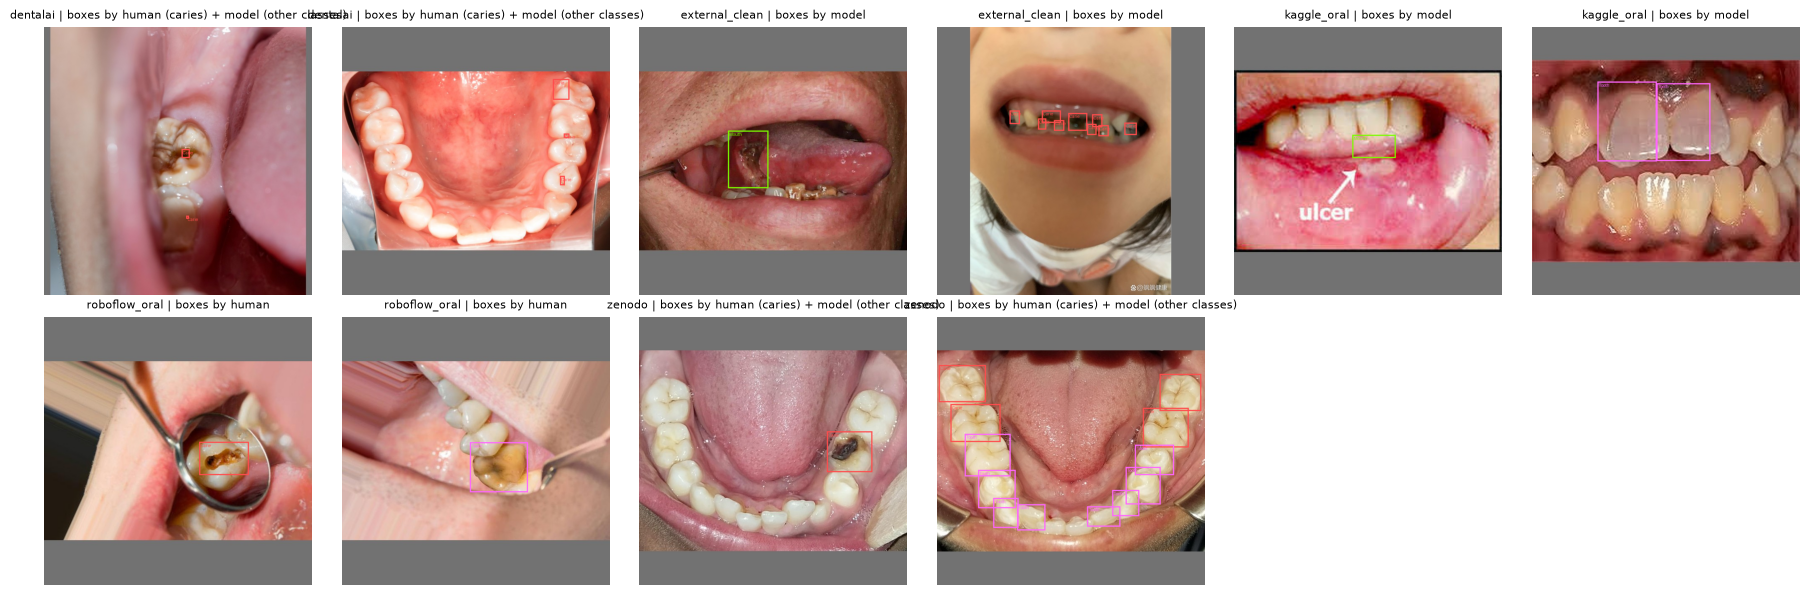

legend: {'Calculus': '#f5c518', 'Caries': '#ff4d4d', 'Hypodontia': '#4dd2ff', 'Mouth_Ulcer': '#7CFC00', 'Tooth_Discoloration': '#ff66ff'}


In [5]:
COLORS = ["#f5c518", "#ff4d4d", "#4dd2ff", "#7CFC00", "#ff66ff"]

def draw(path, boxes, title=None, ax=None):
    # boxes: rows of (cls, cx, cy, w, h[, conf]) with coordinates as fractions
    im = Image.open(path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for b in boxes:
        c, cx, cy, w, h = b[:5]
        d.rectangle([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H],
                    outline=COLORS[int(c)], width=3)
        d.text(((cx - w / 2) * W + 3, (cy - h / 2) * H + 2),
               NAMES[int(c)][:5] + (f" {b[5]:.2f}" if len(b) > 5 else ""), fill=COLORS[int(c)])
    ax.imshow(im); ax.axis("off")
    if title: ax.set_title(title, fontsize=8)

def read_boxes(path):
    lab = DATA_DIR / "labels" / (Path(path).stem + ".txt")
    return [list(map(float, l.split())) for l in lab.read_text().splitlines() if l.strip()]

tr = by_path.loc[LISTS["train"]]
sample = pd.concat([g.sample(min(len(g), 2), random_state=1) for _, g in tr[tr.has_issue.eq(1)].groupby("dataset")])
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, (p, r) in zip(axes.flat, sample.iterrows()):
    draw(p, read_boxes(p), f"{r.dataset} | boxes by {r.boxes_by}", ax)
for ax in axes.flat[len(sample):]: ax.axis("off")
plt.tight_layout(); plt.show()
print("legend:", {n: c for n, c in zip(NAMES, COLORS)})

## 4. Train

If an earlier run with the same name was interrupted (e.g. the laptop slept), it **resumes** from its last
saved epoch instead of starting over.

YOLO starts from weights pre-trained on everyday photos (COCO). Every epoch it sees each training photo once, with
its own random changes (mosaic of 4 photos, flips, scaling, colour). After each epoch it is scored on `val` and the
best epoch is kept as `best.pt`. Training stops early if `val` stops improving for `PATIENCE` epochs. The learning
rate follows a cosine curve, and mosaic is switched off for the last 10 epochs so the model finishes on whole photos.

In [6]:
last = WORK / "runs" / EXPERIMENT / "weights" / "last.pt"
t0 = time.time()
model = None
if last.exists():
    ckpt = torch.load(last, map_location="cpu", weights_only=False)
    if ckpt.get("epoch", -1) >= 0:   # -1 means that run already finished
        print(f"resuming interrupted run after epoch {ckpt['epoch'] + 1}")
        ckpt["train_args"].update(epochs=EPOCHS, workers=WORKERS, patience=PATIENCE)
        torch.save(ckpt, last)
        model = YOLO(str(last))
        model.train(resume=True)
    else:
        print("this run already finished; using its weights")
        model = "finished"
if model is None:
    model = YOLO(str(WORK / MODEL) if (WORK / MODEL).exists() else MODEL)   # downloads pre-trained weights the first time
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, workers=WORKERS,
                patience=PATIENCE, seed=SEED, cos_lr=True, project=str(WORK / "runs"), name=EXPERIMENT,
                exist_ok=True, plots=True, verbose=False)
train_minutes = (time.time() - t0) / 60
RUN_DIR = WORK / "runs" / EXPERIMENT
BEST = RUN_DIR / "weights" / "best.pt"
LR0 = torch.load(BEST, map_location="cpu", weights_only=False)["train_args"]["lr0"]
print(f"trained for {train_minutes:.0f} min in this session -> {BEST}")

resuming interrupted run after epoch 38


New https://pypi.org/project/ultralytics/8.4.213 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.210  Python-3.13.7 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1050 Ti with Max-Q Design, 4096MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.2\Y2_yolo11n_640_v12_train.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001111, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.2\runs\Y2_yolo11n_640_v12\weights\last.pt, momentum=0.937, mosaic=1.0, mult


                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (16,689 outputs left out)

                   all       3341      10120      0.749      0.666      0.722      0.401


Speed: 0.4ms preprocess, 19.9ms inference, 0.0ms loss, 1.7ms postprocess per image


Results saved to D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.2\runs\Y2_yolo11n_640_v12


trained for 416 min in this session -> D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.2\runs\Y2_yolo11n_640_v12\weights\best.pt


### Training curves (`box_loss` = how far boxes are off, `cls_loss` = naming mistakes, `mAP50` on val)

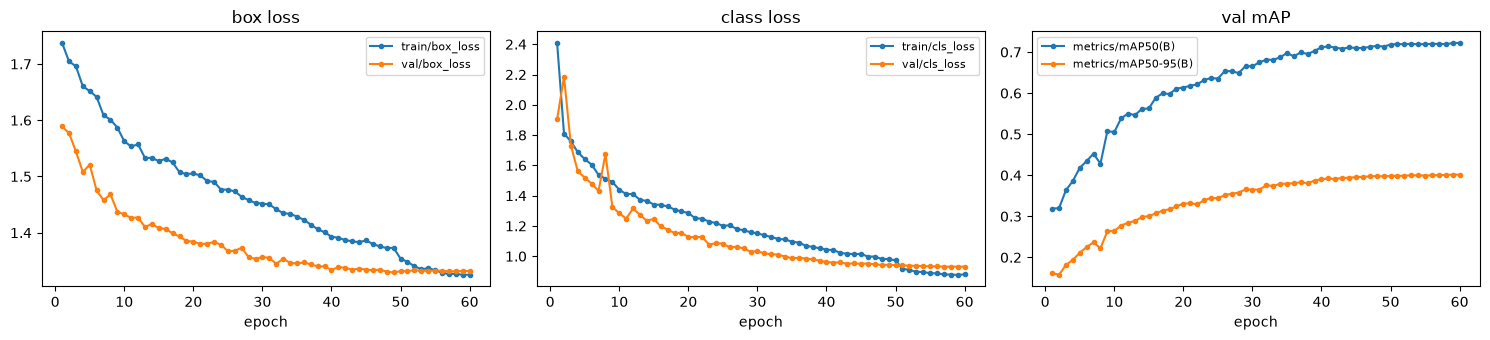

best epoch (Ultralytics fitness on val): 59 of 60


In [7]:
hist = pd.read_csv(RUN_DIR / "results.csv"); hist.columns = hist.columns.str.strip()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (cols, title) in zip(axes, [(["train/box_loss", "val/box_loss"], "box loss"),
                                     (["train/cls_loss", "val/cls_loss"], "class loss"),
                                     (["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "val mAP")]):
    for c in cols:
        ax.plot(hist.epoch, hist[c], marker=".", label=c)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT_DIR / "figures" / f"{EXPERIMENT}_curves.png", dpi=120); plt.show()
fitness = 0.1 * hist["metrics/mAP50(B)"] + 0.9 * hist["metrics/mAP50-95(B)"]   # what Ultralytics uses to pick best.pt
best_epoch = int(hist.loc[fitness.idxmax(), "epoch"])
print("best epoch (Ultralytics fitness on val):", best_epoch, "of", len(hist))

## 5. Box scores on the test sets

`mAP50`: for each class, how well the boxes match the labelled boxes (a box counts if it overlaps at least 50%),
averaged over classes. 1.0 is perfect. `precision`: of the boxes drawn, how many were right. `recall`: of the real
findings, how many got a box.

In [8]:
best = YOLO(str(BEST))
box_results, per_class = {}, []
for name, yml in EVAL_YAMLS.items():
    m = best.val(data=str(yml), split="val", imgsz=IMGSZ, batch=BATCH, workers=WORKERS, plots=True,
                 project=str(WORK / "runs"), name=f"{EXPERIMENT}_{name}", exist_ok=True, verbose=False)
    box_results[name] = dict(mAP50=float(m.box.map50), mAP50_95=float(m.box.map),
                             precision=float(m.box.mp), recall=float(m.box.mr))
    for i, c in enumerate(m.box.ap_class_index):
        per_class.append(dict(set=name, cls=NAMES[int(c)], AP50=float(m.box.ap50[i]),
                              precision=float(m.box.p[i]), recall=float(m.box.r[i])))
box_df = pd.DataFrame(box_results).T[["mAP50", "mAP50_95", "precision", "recall"]]
class_df = pd.DataFrame(per_class).pivot(index="cls", columns="set", values="AP50").reindex(NAMES)
display(box_df.round(3))
print("AP50 per class (test_fair: only DentalAI/Zenodo Caries boxes are human-drawn)")
display(class_df.round(3))

Ultralytics 8.4.210  Python-3.13.7 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1050 Ti with Max-Q Design, 4096MiB)


YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.2±0.0 ms, read: 96.5±27.3 MB/s, size: 56.5 KB)


val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool\labels... 142 images, 45 backgrounds, 0 corrupt: 4% ╸─────────── 142/3046 420.2it/s 0.1s<6.9s

val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool\labels... 298 images, 87 backgrounds, 0 corrupt: 9% ━─────────── 298/3046 754.3it/s 0.2s<3.6s

val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool\labels... 452 images, 128 backgrounds, 0 corrupt: 14% ━╸────────── 452/3046 979.7it/s 0.3s<2.6s

... (293 outputs left out)

Results saved to D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.2\runs\Y2_yolo11n_640_v12_test_fair


,mAP50,mAP50_95,precision,recall
test,0.712,0.384,0.762,0.645
test_fair,0.175,0.111,0.269,0.199


AP50 per class (test_fair: only DentalAI/Zenodo Caries boxes are human-drawn)


set,test,test_fair
cls,,
Calculus,0.509,0.069
Caries,0.736,0.663
Hypodontia,0.720,0.002
Mouth_Ulcer,0.799,0.071
Tooth_Discoloration,0.795,0.070


### Caries on human boxes only

DentalAI and Zenodo caries boxes were drawn by people, so this is the most honest box score outside Roboflow.

In [9]:
human_caries = [p for p in LISTS["test_fair"] if by_path.at[p, "dataset"] in ("dentalai", "zenodo")]
hc_yaml = write_yaml("eval_test_fair_human", write_list("test_fair_human", human_caries))
m = best.val(data=str(hc_yaml), split="val", imgsz=IMGSZ, batch=BATCH, workers=WORKERS, plots=False,
             project=str(WORK / "runs"), name=f"{EXPERIMENT}_test_fair_human", exist_ok=True, verbose=False)
caries_i = list(m.box.ap_class_index).index(1) if 1 in m.box.ap_class_index else None
caries_human = (dict(n_photos=len(human_caries), AP50=float(m.box.ap50[caries_i]), precision=float(m.box.p[caries_i]),
                     recall=float(m.box.r[caries_i])) if caries_i is not None else {})
print("Caries, DentalAI + Zenodo test_fair photos:", {k: round(v, 3) for k, v in caries_human.items()})

Ultralytics 8.4.210  Python-3.13.7 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1050 Ti with Max-Q Design, 4096MiB)


YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 288.1±47.9 MB/s, size: 57.3 KB)


val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool\labels... 113 images, 28 backgrounds, 0 corrupt: 14% ━╸────────── 113/800 337.0it/s 0.1s<2.0s

val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool\labels... 261 images, 74 backgrounds, 0 corrupt: 32% ━━━╸──────── 261/800 672.2it/s 0.2s<0.8s

val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool\labels... 414 images, 125 backgrounds, 0 corrupt: 51% ━━━━━━────── 414/800 927.9it/s 0.3s<0.4s

... (54 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 1.1it/s 44.5s

                   all        800       1959      0.455      0.182      0.184      0.131


Speed: 2.0ms preprocess, 12.3ms inference, 0.0ms loss, 1.5ms postprocess per image


Caries, DentalAI + Zenodo test_fair photos: {'n_photos': 800, 'AP50': 0.71, 'precision': 0.762, 'recall': 0.633}


## 6. Image-level check: does it find *anything* on problem photos, and stay quiet on healthy ones?

This turns the detector into a yes/no screen (any box at confidence >= `CONF` means "problem"), so it can be
compared directly with the stage-1 classifier. ROC-AUC uses the most confident box per photo.

In [10]:
def predict_set(paths):
    out = []
    for i in range(0, len(paths), 64):
        for r in best.predict(paths[i:i + 64], imgsz=IMGSZ, conf=0.01, verbose=False, stream=True):
            b = r.boxes
            out.append(dict(max_conf=float(b.conf.max()) if len(b) else 0.0,
                            boxes=[[int(c), *map(float, xywh), float(cf)]
                                   for c, xywh, cf in zip(b.cls.tolist(), b.xywhn.tolist(), b.conf.tolist()) if cf >= CONF]))
    return out

eval_df = by_path.loc[LISTS["test"]].copy()
eval_df["set"] = "test"
eval_df["fair"] = eval_df.index.isin(set(LISTS["test_fair"]))
preds = predict_set(list(eval_df.index))
eval_df["max_conf"] = [p["max_conf"] for p in preds]
eval_df["pred_boxes"] = [p["boxes"] for p in preds]
eval_df["flagged"] = (eval_df.max_conf >= CONF).astype(int)

def image_scores(g):
    y, p = g.has_issue.values, g.flagged.values
    rec = lambda cls: float((p[y == cls] == cls).mean()) if (y == cls).any() else float("nan")
    return dict(n=len(g), n_issue=int(y.sum()), n_healthy=int((1 - y).sum()), recall_issue=rec(1),
                recall_healthy=rec(0), balanced_accuracy=float(np.nanmean([rec(1), rec(0)])),
                roc_auc=float(roc_auc_score(y, g.max_conf)) if 0 < y.sum() < len(y) else float("nan"))

image_results = {"test_fair": image_scores(eval_df[eval_df.fair]), "test": image_scores(eval_df)}
display(pd.DataFrame(image_results).T.round(3))
by_source = pd.DataFrame({src: image_scores(g) for src, g in eval_df.groupby("dataset")}).T
display(by_source.round(3))

,n,n_issue,n_healthy,recall_issue,recall_healthy,balanced_accuracy,roc_auc
test_fair,1022.0,703.0,319.0,0.822,0.796,0.809,0.904
test,3046.0,2047.0,999.0,0.930,0.932,0.931,0.981


,n,n_issue,n_healthy,recall_issue,recall_healthy,balanced_accuracy,roc_auc
dentalai,455.0,224.0,231.0,0.781,0.766,0.774,0.855
external_clean,63.0,48.0,15.0,0.750,0.800,0.775,0.847
kaggle_oral,159.0,100.0,59.0,0.430,0.949,0.690,0.814
mendeley_noncaries,680.0,0.0,680.0,NaN,0.996,0.996,NaN
roboflow_oral,1344.0,1344.0,0.0,0.987,NaN,0.987,NaN
zenodo,345.0,331.0,14.0,0.979,0.643,0.811,0.975


### Does it work equally on every kind of photo?

Recall per condition: of the test photos that have that condition, how many got at least one box *of that
condition*.

In [11]:
rows = []
for c_i, c in enumerate(NAMES):
    for fair, g in ((True, eval_df[eval_df.fair]), (False, eval_df)):
        g = g[g[c].eq(1)]
        if len(g):
            hit = g.pred_boxes.map(lambda bs: any(int(b[0]) == c_i for b in bs))
            rows.append(dict(condition=c, set="test_fair" if fair else "test", photos=len(g), found=float(hit.mean())))
cond_df = pd.DataFrame(rows).pivot(index="condition", columns="set", values="found").reindex(NAMES)
display(cond_df.round(3))

set,test,test_fair
condition,,
Calculus,0.694,0.412
Caries,0.900,0.867
Hypodontia,0.849,0.250
Mouth_Ulcer,0.889,0.200
Tooth_Discoloration,0.846,0.378


## 7. Examples from the fair test: labelled boxes (left) vs the model's (right)

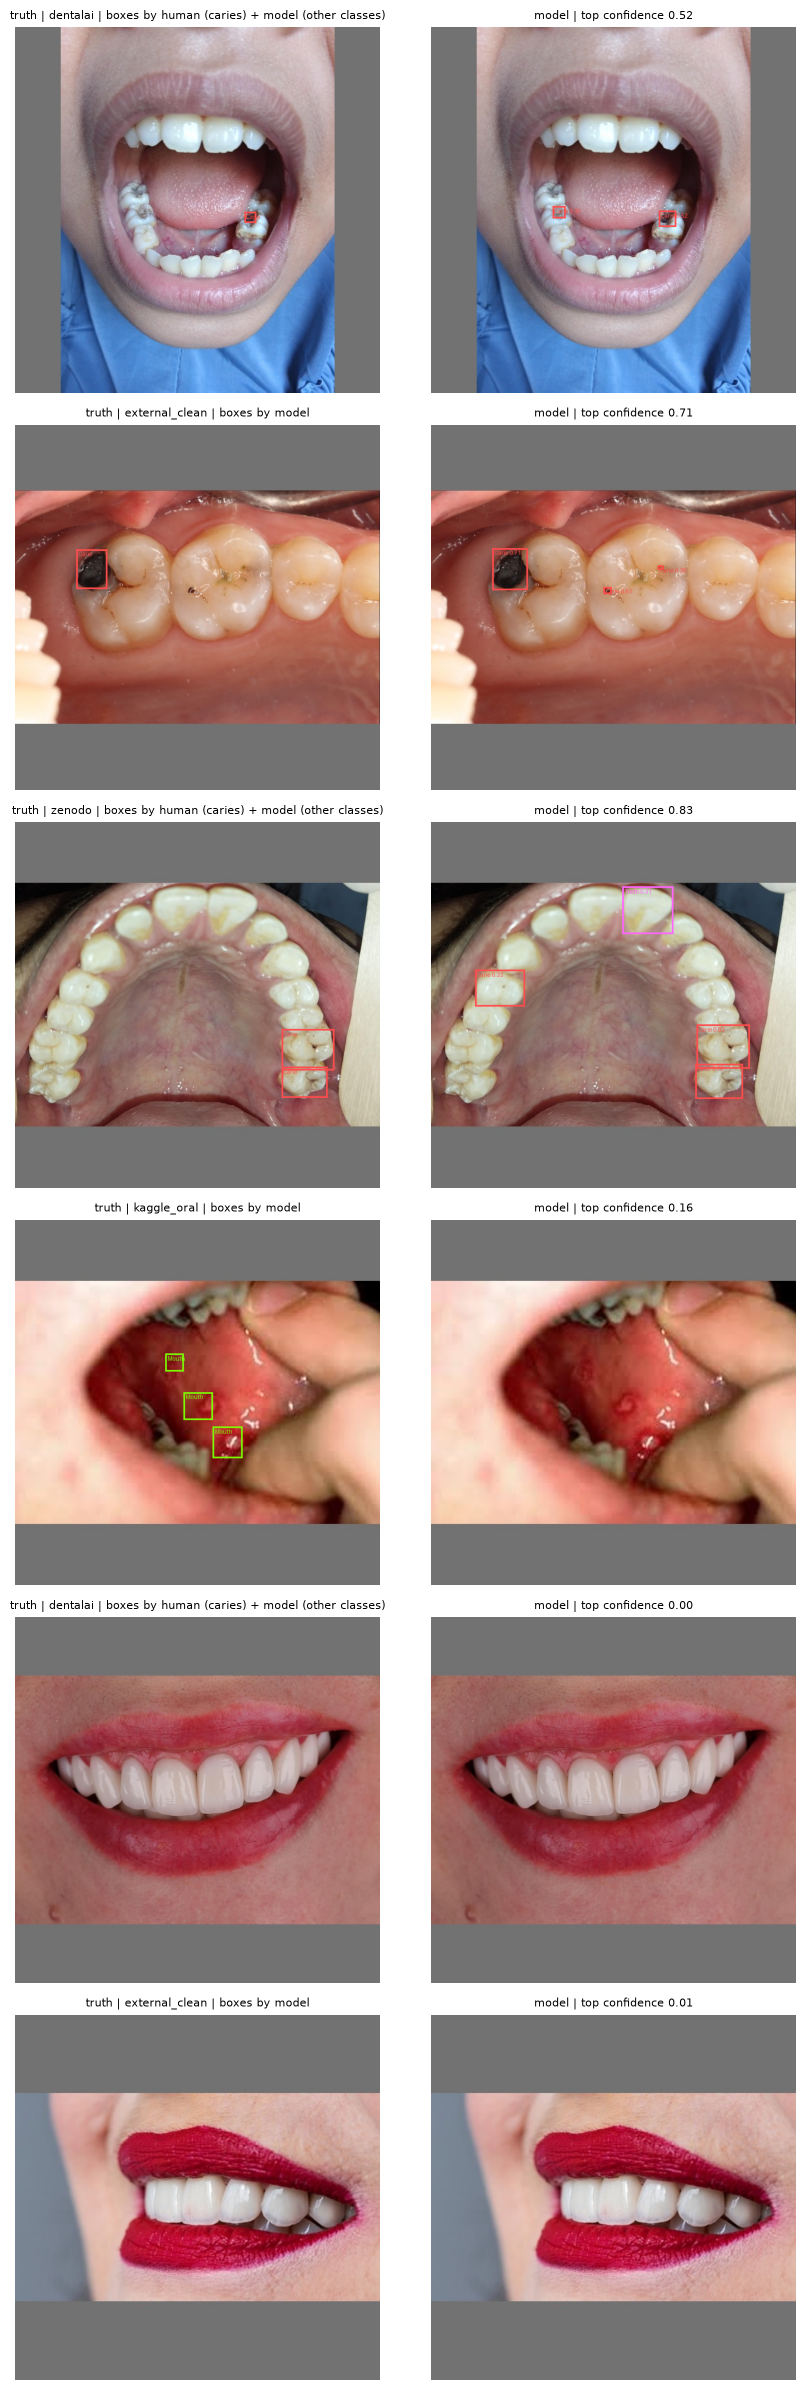

In [12]:
fair = eval_df[eval_df.fair]
ex = pd.concat([fair[fair.has_issue == 1].pipe(lambda g: g.sample(min(len(g), 4), random_state=3)),
                fair[fair.has_issue == 0].pipe(lambda g: g.sample(min(len(g), 2), random_state=3))])
fig, axes = plt.subplots(len(ex), 2, figsize=(9, 4 * len(ex)))
for (a1, a2), (p, r) in zip(axes, ex.iterrows()):
    draw(p, read_boxes(p), f"truth | {r.dataset} | boxes by {r.boxes_by}", a1)
    draw(p, r.pred_boxes, f"model | top confidence {r.max_conf:.2f}", a2)
plt.tight_layout(); fig.savefig(OUT_DIR / "figures" / f"{EXPERIMENT}_examples.png", dpi=100); plt.show()

## 8. Save the model and results

In [13]:
stem = {"Y2_yolo11n": "yolo_detector_v12", "Y3_yolo11s": "yolo_detector_v12_s"}.get(tag, f"yolo_detector_v12_{tag}")
weights_out = WEIGHTS_DIR / (stem + ("_smoke.pt" if SMOKE else ".pt"))
shutil.copyfile(BEST, weights_out)
for f in ("results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"):
    if (RUN_DIR / f).exists():
        shutil.copyfile(RUN_DIR / f, OUT_DIR / "figures" / f"{EXPERIMENT}_{f}")

metrics = dict(experiment=EXPERIMENT, data=str(DATA_DIR), model=MODEL, imgsz=IMGSZ, epochs_run=len(hist),
               best_epoch=best_epoch, train_minutes_this_session=round(train_minutes, 1), conf=CONF,
               set_sizes=summary["photos"].to_dict(), box=box_results,
               per_class_AP50=class_df.round(4).where(class_df.notna(), None).to_dict(),
               caries_human_boxes_test_fair=caries_human,
               image_level=image_results, image_level_by_source=by_source.to_dict("index"),
               condition_found_rate=cond_df.round(4).where(cond_df.notna(), None).to_dict(),
               notes="test_fair = test rows from dentalai/zenodo/kaggle_oral/external_clean; only dentalai/zenodo "
                     "Caries boxes there are human-drawn.")
(OUT_DIR / f"{EXPERIMENT}_metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
hist.to_csv(OUT_DIR / f"{EXPERIMENT}_history.csv", index=False)

if not SMOKE:
    f, t = box_results["test_fair"], box_results["test"]
    row = dict(run_id=EXPERIMENT, date=time.strftime("%Y-%m-%d"), member="Brandon", model=MODEL.replace(".pt", ""),
               data_version="oral_dataset v1.2 (clean Roboflow, deduped, group split)", imgsz=IMGSZ, epochs=len(hist),
               batch=BATCH, lr0=LR0, mAP50=round(f["mAP50"], 4), mAP50_95=round(f["mAP50_95"], 4),
               precision=round(f["precision"], 4), recall=round(f["recall"], 4),
               weights_path=str(weights_out.relative_to(REPO)),
               notes=f"scores = test_fair; full test mAP50 {t['mAP50']:.3f}; best epoch {best_epoch}")
    log = REPO / "models" / "yolo_caries" / "results" / "experiments.csv"
    old = pd.read_csv(log)
    pd.concat([old[old.run_id != EXPERIMENT], pd.DataFrame([row])]).to_csv(log, index=False)
print("saved", weights_out, "and", OUT_DIR / f"{EXPERIMENT}_metrics.json")

saved D:\nyp\Sem 2\AI Innovation Deep learning\Deep-Learning-WIU\models\yolo_caries\weights\Brandon\yolo_detector_v12.pt and D:\nyp\Sem 2\AI Innovation Deep learning\Deep-Learning-WIU\models\yolo_caries\results\Brandon\Y2_yolo11n_640_v12_metrics.json


## 9. Try it on one photo

In [14]:
def detect(path, conf=CONF):
    # What the app would call: boxes with condition names and confidences (a screening aid, not a diagnosis).
    # Photos of any size work: YOLO pads them to 640x640 with the same grey as the training photos.
    r = best.predict(str(path), imgsz=IMGSZ, conf=conf, verbose=False)[0]
    return [dict(condition=NAMES[int(c)], confidence=round(float(cf), 3), box_xyxy=[round(v) for v in b])
            for c, cf, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]

demo = fair[fair.has_issue == 1].index[0]
print({c: int(by_path.at[demo, c]) for c in NAMES}); detect(demo)

{'Calculus': 0, 'Caries': 1, 'Hypodontia': 0, 'Mouth_Ulcer': 0, 'Tooth_Discoloration': 0}


[]

## 10. Results and limitations (run of 15-16 Nov 2026: 60 epochs, best epoch 59)

**Box scores**

| | test_fair (quote first) | test (all) |
|---|---|---|
| photos | 1,022 | 3,046 |
| mAP50 | 0.175 | 0.712 |
| precision | 0.269 | 0.762 |
| recall | 0.199 | 0.645 |
| **Caries on human boxes (DentalAI + Zenodo, 800 photos)** | **AP50 0.710** (P 0.76, R 0.63) | |

**AP50 per class**

| class | test (Roboflow: human boxes) | test_fair (mostly Qwen boxes) |
|---|---|---|
| Calculus | 0.509 | 0.069 |
| Caries | 0.736 | 0.663 |
| Hypodontia | 0.720 | 0.002 |
| Mouth_Ulcer | 0.799 | 0.071 |
| Tooth_Discoloration | 0.795 | 0.070 |

**Image level ("any box at confidence 0.25?")**

| | test_fair | test |
|---|---|---|
| problem photos flagged | 0.822 | 0.930 |
| healthy photos left alone | 0.796 | 0.932 |
| balanced accuracy | 0.809 | 0.931 |
| ROC-AUC | 0.904 | 0.981 |

Stage-1 classifier on the same test_fair photos: balanced accuracy 0.819, AUC 0.923. The detector is nearly as good
at "problem or not".

**Compared with notebook 02 (v1.1)**: full-test mAP50 0.685 -> 0.712 (Calculus 0.43 -> 0.51, Hypodontia
0.56 -> 0.72), now on clean originals with no duplicate copies, so this is the more honest number. The two
test_fair sets are different (v1.1: 772 DentalAI/Zenodo photos), so those numbers can't be compared directly.

**Limitations to state in the report**
- Outside Roboflow, only Caries has human boxes. The low test_fair scores for the other conditions measure
  agreement with Qwen's boxes, which may themselves be wrong, so they say little either way.
- Kaggle problem photos: only 43% get any box (Qwen boxes, a different photo style). DentalAI healthy photos: 77% are
  left alone, versus 99.6% of Mendeley healthy photos. The source shortcut is smaller than in v1.1 but still there.
- Zenodo has only 14 healthy test photos, so its healthy score (0.64) is very uncertain.
- No phone selfies in any test set yet; the real-world photo test is still needed.
- Best epoch was 59 of 60, so a longer run might still gain a little.
